# 04. 실제 데이터 이상 탐지
**데이터**: 허브 유동인구(583) 2024-04-01~2025-03-31(12개월). 끝까지 받은 달만 쓴다(아래 첫 셀에서 기간·행 수 확인).

**방법** (`app/analytics/detect.py`)
- `seasonal_z`: 같은 요일 앞뒤 4주 값의 중앙값을 기대값으로, 잔차를 MAD로 표준화한 점수
- `robust_resid`: STL(주기 7, seasonal=13, trend=29) 분해 잔차를 MAD로 표준화
- 수집되지 않은 날은 이상으로 보지 않음, 연속 이상일은 '구간'으로 묶음(3일 이상 = 지속 변화)

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False

In [2]:
from app.store.cache import CacheStore
from app.analytics.detect import detect_anomalies, group_episodes
st = CacheStore("data/cache")
pop = st._read("pop_domestic")
print(f"유동인구 {len(pop):,}행, 기간 {pop['baseDate'].min()} ~ {pop['baseDate'].max()}, 날짜 {pop['baseDate'].nunique()}일")
rows, eps = [], []
for emd in st.regions("유동인구"):
    s = st.series("유동인구", emd)
    for m in ["seasonal_z", "robust_resid"]:
        found = detect_anomalies(s, method=m, threshold=3.5)
        rows += [{"읍면동": emd, "방법": m, "날짜": a.date.date(), "기대 대비(%)": round(a.pct * 100, 1), "점수": round(a.score, 1)} for a in found]
        eps += [{"읍면동": emd, "방법": m, "시작": e.start.date(), "끝": e.end.date(), "일수": e.days, "유형": e.kind,
                 "최대일": e.peak.date.date(), "기대 대비(%)": round(e.peak.pct * 100, 1), "점수": round(e.peak.score, 1)} for e in group_episodes(found)]
an, ep = pd.DataFrame(rows), pd.DataFrame(eps)
print(f"읍면동 {an['읍면동'].nunique()}곳 · 방법별 이상일:", an.groupby("방법").size().to_dict(), "· 방법별 구간:", ep.groupby("방법").size().to_dict())
both = an.pivot_table(index=["읍면동", "날짜"], columns="방법", values="점수").dropna()
print("두 방법이 모두 잡은 이상일:", len(both))

유동인구 251,104행, 기간 20240401 ~ 20250331, 날짜 365일


읍면동 43곳 · 방법별 이상일: {'robust_resid': 1237, 'seasonal_z': 441} · 방법별 구간: {'robust_resid': 582, 'seasonal_z': 185}
두 방법이 모두 잡은 이상일: 432


## 이상일이 많이 겹친 날 — 여러 읍면동이 동시에 움직인 날은 제주 전체 요인(연휴·성수기) 가능성

In [3]:
top_days = an[an["방법"] == "seasonal_z"]["날짜"].value_counts().head(8).rename_axis("날짜").reset_index(name="이상 읍면동 수")
from app.analytics.context import KR_HOLIDAYS
top_days["공휴일"] = top_days["날짜"].map(lambda d: KR_HOLIDAYS.get(d, ""))
top_days

,날짜,이상 읍면동 수,공휴일
0,2024-09-16,35,추석 전날
1,2025-01-29,34,설날
2,2024-09-17,32,추석
3,2024-07-31,26,
4,2025-01-28,24,설날 전날
5,2025-01-30,23,설날 다음날
6,2024-08-01,22,
7,2024-08-02,21,


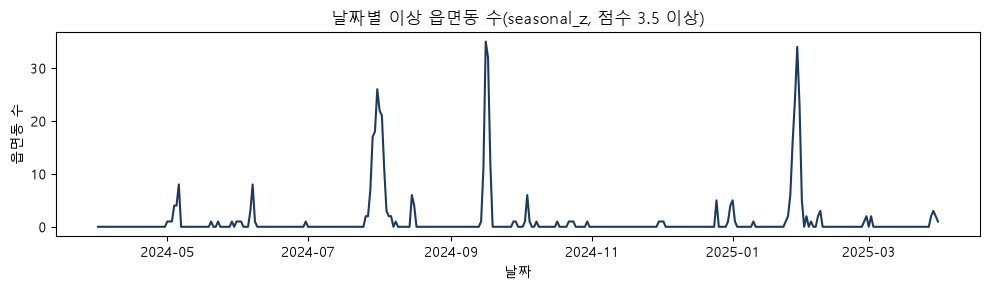

In [4]:
lo, hi = pd.to_datetime(pop["baseDate"].astype(str)).agg(["min", "max"])
daily = an[an["방법"] == "seasonal_z"].groupby("날짜").size().reindex(pd.date_range(lo, hi).date, fill_value=0)
ax = daily.plot(figsize=(10, 3), color="#1F3A5F", title="날짜별 이상 읍면동 수(seasonal_z, 점수 3.5 이상)")
ax.set_ylabel("읍면동 수"); plt.tight_layout()

## 점수가 큰 이상 구간 상위 10개 (seasonal_z)

In [5]:
ep[ep["방법"] == "seasonal_z"].sort_values("점수", key=abs, ascending=False).head(10).reset_index(drop=True)

,읍면동,방법,시작,끝,일수,유형,최대일,기대 대비(%),점수
0,제주시 삼도1동,seasonal_z,2025-03-28,2025-03-30,3,지속 변화,2025-03-30,170.1,29.1
1,서귀포시 효돈동,seasonal_z,2025-01-27,2025-01-30,4,지속 변화,2025-01-29,249.5,20.7
2,서귀포시 효돈동,seasonal_z,2024-09-15,2024-09-18,4,지속 변화,2024-09-17,243.0,18.6
3,제주시 일도2동,seasonal_z,2025-01-25,2025-01-31,7,지속 변화,2025-01-29,93.3,15.9
4,제주시 이호동,seasonal_z,2024-07-26,2024-07-29,4,지속 변화,2024-07-28,103.8,15.7
5,제주시 삼양동,seasonal_z,2025-01-27,2025-01-31,5,지속 변화,2025-01-29,103.6,14.4
6,제주시 화북동,seasonal_z,2025-01-24,2025-01-31,8,지속 변화,2025-01-29,75.6,13.2
7,제주시 삼양동,seasonal_z,2024-09-15,2024-09-18,4,지속 변화,2024-09-17,87.4,12.5
8,제주시 일도2동,seasonal_z,2024-09-15,2024-09-18,4,지속 변화,2024-09-17,71.6,12.3
9,서귀포시 서홍동,seasonal_z,2025-01-28,2025-01-30,3,지속 변화,2025-01-29,85.9,12.2


## 예시: 제주시 이호동 — 실제 값과 기대값

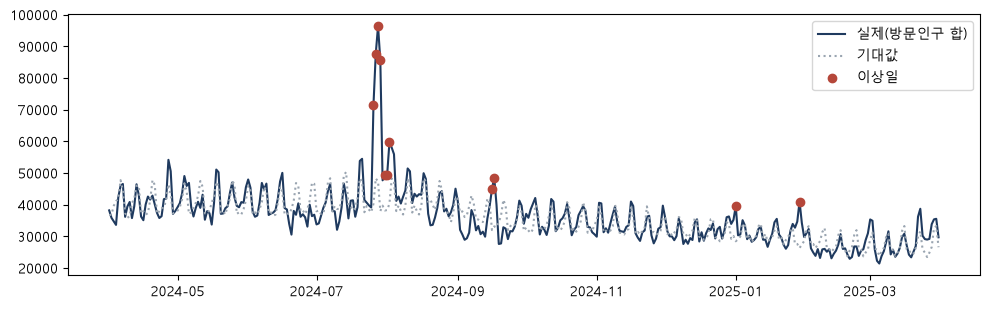

In [6]:
from app.analytics.detect import score_series
s = st.series("유동인구", "제주시 이호동"); _, exp, z = score_series(s, "seasonal_z")
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(s.index, s.values, color="#1F3A5F", label="실제(방문인구 합)"); ax.plot(exp.index, exp.values, ":", color="#9AA5B1", label="기대값")
hit = z[z.abs() >= 3.5].dropna(); ax.scatter(hit.index, s.reindex(hit.index), color="#B5473A", zorder=3, label="이상일")
ax.legend(); plt.tight_layout()

**읽은 것** (2024-04-01~2025-03-31, 43개 읍면동, 점수 3.5 기준)
- 이상 읍면동이 가장 많은 날은 추석(2024-09-16·17)과 설날(2025-01-28~30) → 여러 곳이 동시에 움직인 날은 '공휴일·연휴' 원인 후보
- 7월 말~8월 초(2024-07-31, 08-01·02)에도 20곳 이상이 함께 증가 → 공휴일이 아니므로 여름 성수기(제주 전체 동반 변화)로 본다. 이호동 07-26~29(+104%)가 대표 사례
- 점수 1위는 삼도1동 2025-03-28~30(기대 대비 +170%). 같은 날 와이파이(점수 13.7)·버스도 함께 늘어 데이터 오류로 보기는 어렵다. 기상·공휴일·축제 자료(761)에는 맞는 사건이 없다. 삼도1동을 뺀 제주 전체 와이파이도 같은 날 늘어(점수 4.1) 판정 모델은 '관광 수요 변화'(62.5%, 판단 불가 34.5%)로 보았지만, **실제 사건은 미확인**이다
- 같은 기준에서 STL 잔차(robust_resid)는 이상일을 약 3배 많이 낸다(1,237 vs 441). 가짜 이상 주입 평가에서 같은 경보 빈도로 맞추면 재현율 차이가 작아(유동인구 +2.1%p), 설명하기 쉬운 같은 요일 중앙값을 기본으로 둔다
- 한계: 1년치라 '작년 같은 달' 비교는 못 함, 시리즈 끝(2025-03-31)은 앞쪽 데이터만으로 기준선을 잡음